In [73]:
import pandas as pd
import scipy
import sklearn
import numpy as np

Agent =
1. device forwarding/modifying the traffic
NAT device (e.g., home router translating private → public IP)

Web proxy server

Load balancer

Firewall or gateway

2. Monitoring agent:
SIEM agents (e.g., Splunk, Wazuh)

EDR/XDR security agents

Packet capture agents

SNMP agents

3. Application Agents:
Backup agents

VPN clients

Remote management agents

Docker/Kubernetes node agents

4. Cloud Services / SaaS Middleman

In [74]:
col_names = ["Flow", "Agent IP", "src Port", "dst Port", "src_MAC", "dst_MAC", "ethernet_type", "dst vlan", "src vlan", "src_ip", "dst_ip", "tcp6 udp17", "ip_type_of_service", "ip_time_to_live", "src port transport level", "dst port transport level", "tcp flags", "packet size", "ip size", "sampling rate"]
df_data_2 = pd.read_csv("./Data/Data_2.csv", names = col_names, dtype= str)
df_test_SFlow = pd.read_csv("./Data/test_SFLow_data.csv", names = col_names, dtype= str)

In [75]:
display(df_data_2.head())
display(df_test_SFlow.head())
print("df data shape", df_data_2.shape)
print("df test shape", df_test_SFlow.shape)

,Flow,Agent IP,src Port,dst Port,src_MAC,dst_MAC,ethernet_type,dst vlan,src vlan,src_ip,dst_ip,tcp6 udp17,ip_type_of_service,ip_time_to_live,src port transport level,dst port transport level,tcp flags,packet size,ip size,sampling rate
0,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919,919,74.125.10.59,137.132.38.238,17,0x00,63,443,62758,0x00,1396,1378,2048
1,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919,919,173.194.22.215,137.132.228.29,6,0x00,63,443,39740,0x10,1438,1420,2048
2,FLOW,203.30.38.251,199,131,544b8cf9a7df,001cb0c88e40,0x0800,600,43,193.62.193.9,202.130.56.153,6,0x00,246,80,35794,0x18,272,250,2048
3,FLOW,203.30.38.251,193,131,0031466b23cf,001cb0c88e40,0x0800,919,43,74.125.130.132,192.122.131.33,6,0x00,52,443,5287,0x10,1418,1400,2048
4,FLOW,203.30.38.251,129,193,00135f21bc80,0031466b23cf,0x0800,11,919,155.69.160.69,74.125.68.139,17,0x60,59,48361,443,0x00,89,67,2048


,Flow,Agent IP,src Port,dst Port,src_MAC,dst_MAC,ethernet_type,dst vlan,src vlan,src_ip,dst_ip,tcp6 udp17,ip_type_of_service,ip_time_to_live,src port transport level,dst port transport level,tcp flags,packet size,ip size,sampling rate
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN
FLOW,aa.aa.aa.aa,258,20,204e71cf1b0f,002438aa0a00,0x0800,3012,3012,152.3.219.19,198.71.44.98,50,0x00,245,0,0,0x00,1518,1496,2048,NaN


df data shape (177232, 20)
df test shape (1200, 20)


### Mac Analysis

In [ ]:
# looks like a lot of the source macs are in scientific notation in source data. 
# Discard these data for MAC address analysis
mac_df = df_data_2[~df_data_2["src_MAC"].str.contains(r"E", na=False) 
                   & ~(df_data_2["src_MAC"] == "1")
                   & ~df_data_2["dst_MAC"].str.contains(r"E", na=False)
                   & ~(df_data_2["dst_MAC"] == "1")]
display(mac_df)

,Flow,Agent IP,src Port,dst Port,src_MAC,dst_MAC,ethernet_type,dst vlan,src vlan,src_ip,dst_ip,tcp6 udp17,ip_type_of_service,ip_time_to_live,src port transport level,dst port transport level,tcp flags,packet size,ip size,sampling rate
0,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919,919,74.125.10.59,137.132.38.238,17,0x00,63,443,62758,0x00,1396,1378,2048
1,FLOW,203.30.38.251,193,130,0031466b23cf,00239cd087c1,0x0800,919,919,173.194.22.215,137.132.228.29,6,0x00,63,443,39740,0x10,1438,1420,2048
2,FLOW,203.30.38.251,199,131,544b8cf9a7df,001cb0c88e40,0x0800,600,43,193.62.193.9,202.130.56.153,6,0x00,246,80,35794,0x18,272,250,2048
3,FLOW,203.30.38.251,193,131,0031466b23cf,001cb0c88e40,0x0800,919,43,74.125.130.132,192.122.131.33,6,0x00,52,443,5287,0x10,1418,1400,2048
4,FLOW,203.30.38.251,129,193,00135f21bc80,0031466b23cf,0x0800,11,919,155.69.160.69,74.125.68.139,17,0x60,59,48361,443,0x00,89,67,2048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
177227,FLOW,203.30.38.251,193,131,0031466b23cf,001cb0c88e40,0x0800,919,43,74.125.10.23,192.122.131.146,6,0x00,63,443,50177,0x10,1490,1472,2048
177228,FLOW,203.30.38.251,200,199,80711fc76001,ccef48570144,0x0800,4095,601,13.107.4.50,210.48.222.13,6,0x00,112,80,50771,0x10,1448,1426,2048
177229,FLOW,203.30.38.251,200,131,80711fc76001,001cb0c88e40,0x0800,280,43,171.67.77.19,192.122.131.36,6,0x00,56,80,10452,0x10,1522,1500,2048
177230,FLOW,203.30.38.251,199,129,544b8cf9a7df,00135f21bc80,0x0800,600,11,133.11.245.204,155.69.59.240,17,0x00,55,50553,4500,0x10,150,128,2048


In [ ]:
# Curious about srcs that arent dsts and vice versa

# Stack src and dst MACs into one long column for counting
all_macs = pd.concat([mac_df["src_MAC"], mac_df["dst_MAC"]])

# Count total transmissions involving each MAC (either as src or dst)
mac_counts = all_macs.value_counts().reset_index()
mac_counts.columns = ["MAC", "total_transmissions"]

# MACs that are destinations but not sources
dst_not_src_MAC = np.setdiff1d(mac_df["dst_MAC"].unique(), mac_df["src_MAC"].unique())
# MACs that are sources but not destinations
src_not_dst_MAC = np.setdiff1d(mac_df["src_MAC"].unique(), mac_df["dst_MAC"].unique())

# Filter counts for those MACs only, then sort descending
dst_only_counts = mac_counts[mac_counts["MAC"].isin(dst_not_src_MAC)].sort_values("total_transmissions", ascending=False)
src_only_counts = mac_counts[mac_counts["MAC"].isin(src_not_dst_MAC)].sort_values("total_transmissions", ascending=False)

print("=== Destination-only MACs (not seen as source) ===")
display(dst_only_counts)

print("\n=== Source-only MACs (not seen as destination) ===")
display(src_only_counts)

=== Destination-only MACs (not seen as source) ===


,MAC,total_transmissions
13,2c2172f7f437,5462
29,00055f1b7242,84
39,0881f4ed0fc0,29
43,88e0f3c33853,22
51,2c2172d57648,14
53,ffffffffffff,9
55,cc4e249c6300,8
61,0022be65f000,4
62,b0a86e7667f0,4
65,2c6bf5d277ca,3



=== Source-only MACs (not seen as destination) ===


,MAC,total_transmissions
16,5c5eabb2a7cd,1538
24,84b59cfbe2b2,190
28,00239cdbae77,88
34,00155dfbf011,49
36,cc4e249b8a00,40
49,00270dc96840,14
57,2c6bf5e84339,6
68,00a0de37fc83,2
69,64f69dd64b9e,2
84,5475d0a427c1,1


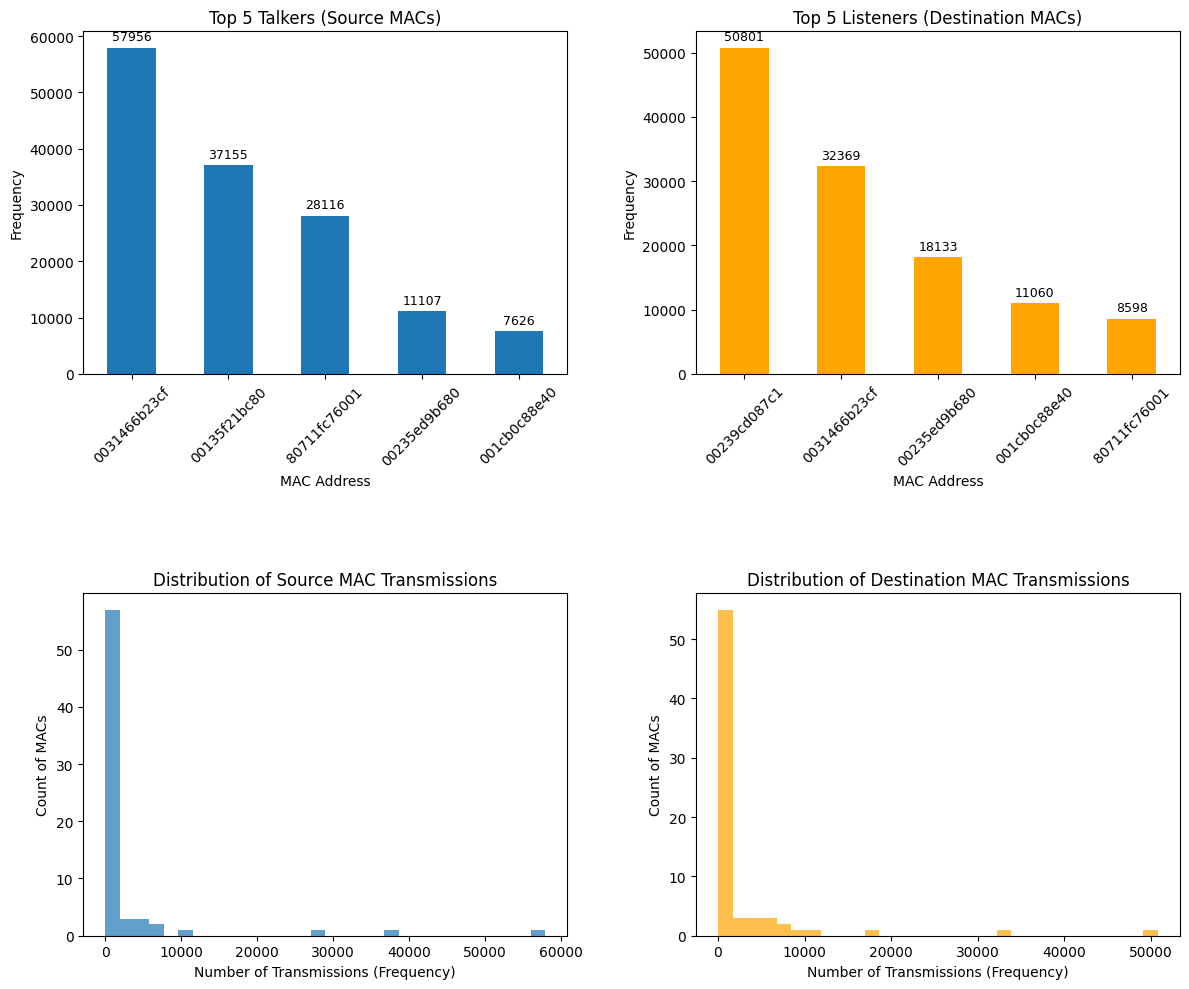

In [ ]:
import matplotlib.pyplot as plt

# Prepare frequency DataFrames. 
# Turns out reset index causes ascending order, so no need sort_values("frequency", ascending=False) 
df_src_mac_freq = mac_df["src_MAC"].value_counts().reset_index().set_axis(["MAC", "frequency"], axis=1)
df_dst_mac_freq = mac_df["dst_MAC"].value_counts().reset_index().set_axis(["MAC", "frequency"], axis=1)

top_n = 5

fig, axes = plt.subplots(2, 2, figsize=(12, 10)) 

# --- Row 1, Col 1: Top N Source MACs ---
bar_src = df_src_mac_freq.head(top_n).plot(
    kind="bar",
    x="MAC",
    y="frequency",
    legend=False,
    ax=axes[0, 0]
)
axes[0, 0].set_title(f"Top {top_n} Talkers (Source MACs)")
axes[0, 0].set_xlabel("MAC Address")
axes[0, 0].set_ylabel("Frequency")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].bar_label(bar_src.containers[0], label_type="edge", padding=3, fontsize=9)

# --- Row 1, Col 2: Top N Destination MACs ---
bar_dst = df_dst_mac_freq.head(top_n).plot(
    kind="bar",
    x="MAC",
    y="frequency",
    legend=False,
    ax=axes[0, 1],
    color="orange"
)
axes[0, 1].set_title(f"Top {top_n} Listeners (Destination MACs)")
axes[0, 1].set_xlabel("MAC Address")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].bar_label(bar_dst.containers[0], label_type="edge", padding=3, fontsize=9)

# --- Row 2, Col 1: Histogram for Source MAC frequencies ---
axes[1, 0].hist(df_src_mac_freq["frequency"], bins=30, alpha=0.7)
axes[1, 0].set_title("Distribution of Source MAC Transmissions")
axes[1, 0].set_xlabel("Number of Transmissions (Frequency)")
axes[1, 0].set_ylabel("Count of MACs")

# --- Row 2, Col 2: Histogram for Destination MAC frequencies ---
axes[1, 1].hist(df_dst_mac_freq["frequency"], bins=30, color="orange", alpha=0.7)
axes[1, 1].set_title("Distribution of Destination MAC Transmissions")
axes[1, 1].set_xlabel("Number of Transmissions (Frequency)")
axes[1, 1].set_ylabel("Count of MACs")

# the lack of padding is triggering my ocd
plt.tight_layout(w_pad=4.0, h_pad=6.0)
plt.show()


### Ports

In [104]:
PORT_APP_MAP = {
    80: "HTTP",
    443: "HTTPS",
    53: "DNS",
    22: "SSH",
    25: "SMTP",
    110: "POP3",
    143: "IMAP",
    123: "NTP",
    20: "FTP-Data",
    21: "FTP-Control",
    67: "DHCP-Server",
    68: "DHCP-Client",
    161: "SNMP",
    445: "SMB",
    3306: "MySQL",
    5432: "PostgreSQL",
    6379: "Redis",
    8080: "HTTP-Alt"
}


In [105]:
def infer_application(row):
    ports = [row["src Port"], row["dst Port"]]
    for p in ports:
        try:
            p = int(p)
            if p in PORT_APP_MAP:
                return PORT_APP_MAP[p]
        except:
            pass
    return "Unknown"

df_data_2.loc[:,"application"] = df_data_2.apply(infer_application, axis=1)

In [137]:
def draw_1_var_bar_chart(field_name, df, top_n: int = 5, ax=None):
    """
    Draw a top-N bar chart for a single column in df, with counts and percentage labels.
    
    Parameters:
        field_name (str): column name to plot
        df (pd.DataFrame): the DataFrame containing the data
        top_n (int): number of top categories to display
        ax (matplotlib.axes.Axes): optional, axes to plot on
    """
    if field_name not in df.columns:
        raise ValueError(f"{field_name} is not in df columns")
    
    # Count frequencies
    freq_df = df[field_name].value_counts().reset_index()
    freq_df.columns = [field_name, "frequency"]
    
    total = freq_df["frequency"].sum()  # total samples for percentage calculation
    
    # If no ax provided, create one
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    
    # Plot top N
    bar = freq_df.head(top_n).plot(
        kind="bar",
        x=field_name,
        y="frequency",
        legend=False,
        ax=ax,
        color="tab:blue"
    )
    
    ax.set_title(f"Top {top_n} {field_name}")
    ax.set_xlabel(field_name)
    ax.set_ylabel("Frequency")
    ax.tick_params(axis="x", rotation=45)
    ax.margins(y=0.3)

    # Add labels with counts and percentage
    labels = [f"{count}\n{count/total*100:.1f}%" for count in freq_df.head(top_n)["frequency"]]
    ax.bar_label(bar.containers[0], labels=labels, label_type="edge", padding=3, fontsize=9)
    
    return ax


<Axes: title={'center': 'Top 5 dst Port'}, xlabel='dst Port', ylabel='Frequency'>

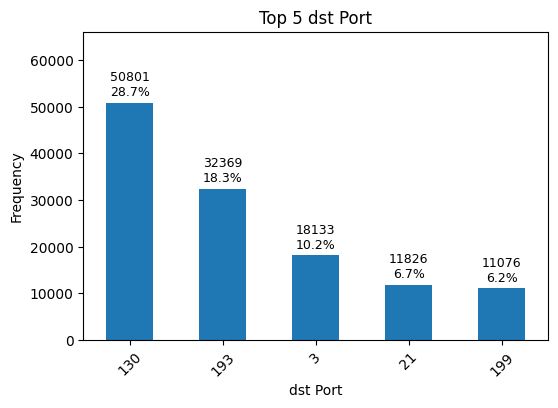

In [138]:
draw_1_var_bar_chart("dst Port", df_data_2)

In [ ]:
application_freq = df_data_2.apply(infer_application, axis=1).value_counts().reset_index()
df_data_2["dst Port"] = pd.to_numeric(df_data_2["dst Port"], errors="raise")
print("Port numbers")
port_number_df = df_data_2["dst Port"].value_counts().reset_index()
display(port_number_df)
print("Applications")
display(application_freq)

Port numbers


,dst Port,count
0,130,50801
1,193,32369
2,3,18133
3,21,11826
4,199,11076
5,131,11060
6,200,8598
7,129,8111
8,14,5735
9,136,4375


Applications


,index,count
0,Unknown,161227
1,FTP-Control,14950
2,FTP-Data,971
3,SSH,84


In [ ]:
import requests

ip = "203.30.38.251"
response = requests.get(f"https://ipinfo.io/{ip}/json")
data = response.json()

display(pd.DataFrame([data]))
# Looks like the research institution has a VPN/something similar and is intentionally hiding port

,ip,city,region,country,loc,org,postal,timezone,readme
0,203.30.38.251,Singapore,Singapore,SG,"1.2897,103.8501",AS23855 Singapore Advanced Research and Educat...,018989,Asia/Singapore,https://ipinfo.io/missingauth
